# Phase 4: Machine Learning - is this case Measles?
**Target:** `IsMeasles` = 1 if the disease is Measles, 0 for any other disease (Mpox, AEFI, Yellow fever ...).
We train on `cleaned_train.csv` and test **once** on `cleaned_test.csv`.

Run `01_clean_data.ipynb` first. Takes about 1-2 minutes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

train = pd.read_csv("outputs/cleaned_train.csv")
test = pd.read_csv("outputs/cleaned_test.csv")

## 1. Target variable

In [2]:
train["IsMeasles"] = (train["Disease/Condition"].str.lower() == "measles").astype(int)
test["IsMeasles"] = (test["Disease/Condition"].str.lower() == "measles").astype(int)

train["IsMeasles"].value_counts(normalize=True)

IsMeasles
1    0.802289
0    0.197711
Name: proportion, dtype: float64

## 2. Features
Symptoms are free text, so we create one 1/0 column per symptom with `.str.contains` (class notes: *Working with text*).

In [3]:
symptoms = {
    "sym_rash": "rash",
    "sym_fever": "fever",
    "sym_cough": "cough",
    "sym_coryza_conjunctivitis": "coryza|conjunctiv|red eye|running nose|runny",
    "sym_headache": "headache",
    "sym_pus_lesions": "pus|lesion|blister|vesic",
    "sym_injection_site": "injection|vaccine site|swollen site|redness",
    "sym_swelling": "lymph|swollen neck|swelling",
    "sym_pain": "pain|myalgia|body ache",
    "sym_vomiting": "vomi",
}

def add_symptom_columns(df):
    text = (df["Signs & Symptoms"].fillna("") + " " + df["Others Signs & Symptoms"].fillna("")).str.lower()
    for column, words in symptoms.items():
        df[column] = text.str.contains(words).astype(int)
    df["sym_count"] = df[list(symptoms)].sum(axis=1)
    return df

train = add_symptom_columns(train)
test = add_symptom_columns(test)
train[list(symptoms)].mean().round(2)

sym_rash                     0.84
sym_fever                    0.83
sym_cough                    0.45
sym_coryza_conjunctivitis    0.37
sym_headache                 0.19
sym_pus_lesions              0.00
sym_injection_site           0.03
sym_swelling                 0.01
sym_pain                     0.11
sym_vomiting                 0.03
dtype: float64

In [4]:
numeric_features = ["Age in Years", "sym_count"] + list(symptoms)
category_features = ["Patient Sex", "Reporting District", "Reporting County", "Admission status", "Vaccination Status"]

# NOT used - they cause target leakage (decided AFTER the diagnosis), see Q4.1:
leakage_columns = ["Final Laboratory Result", "Final Epi-classification", "Rubella Results", "Outcome"]

def make_features(df):
    X = df[numeric_features + category_features].copy()
    X["Age in Years"] = X["Age in Years"].fillna(train["Age in Years"].median())   # missing age -> median
    X[category_features] = X[category_features].fillna("Missing")                  # missing text -> "Missing"
    for column in category_features:
        X[column] = X[column].str.strip()
    return pd.get_dummies(X, columns=category_features)                           # one-hot encoding

X_train = make_features(train)
X_test = make_features(test).reindex(columns=X_train.columns, fill_value=0)   # same columns as train
y_train = train["IsMeasles"]
y_test = test["IsMeasles"]

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4107, 122)  Test: (1027, 122)


## 3. Train two models with 5-fold cross-validation + hyperparameter tuning
`GridSearchCV` tries every combination of settings, each one checked with 5-fold cross-validation on the training data.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_reg = GridSearchCV(
    LogisticRegression(max_iter=3000, class_weight="balanced"),
    param_grid={"C": [0.01, 0.1, 1, 10]},
    cv=cv, scoring="roc_auc",
)
log_reg.fit(X_train, y_train)

forest = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight="balanced"),
    param_grid={"n_estimators": [200, 400], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 3]},
    cv=cv, scoring="roc_auc",
)
forest.fit(X_train, y_train)

print("Logistic Regression - best settings:", log_reg.best_params_, " CV ROC-AUC:", round(log_reg.best_score_, 4))
print("Random Forest       - best settings:", forest.best_params_, " CV ROC-AUC:", round(forest.best_score_, 4))

Logistic Regression - best settings: {'C': 1}  CV ROC-AUC: 0.9745
Random Forest       - best settings: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}  CV ROC-AUC: 0.9879


## 4. Evaluate both models on the held-out test data

In [6]:
results = []
for name, model in [("Logistic Regression", log_reg), ("Random Forest", forest)]:
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    results.append([name,
                    accuracy_score(y_test, predictions), precision_score(y_test, predictions),
                    recall_score(y_test, predictions), f1_score(y_test, predictions),
                    roc_auc_score(y_test, probabilities)])

results = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).round(4)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9396,0.9847,0.9393,0.9615,0.9796
1,Random Forest,0.9669,0.9865,0.9721,0.9792,0.9944


In [7]:
best_name = results.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
best = forest if best_name == "Random Forest" else log_reg
print("Best model:", best_name)

best_predictions = best.predict(X_test)
print(classification_report(y_test, best_predictions, target_names=["Other (0)", "Measles (1)"], digits=3))

Best model: Random Forest
              precision    recall  f1-score   support

   Other (0)      0.893     0.946     0.919       203
 Measles (1)      0.986     0.972     0.979       824

    accuracy                          0.967      1027
   macro avg      0.940     0.959     0.949      1027
weighted avg      0.968     0.967     0.967      1027



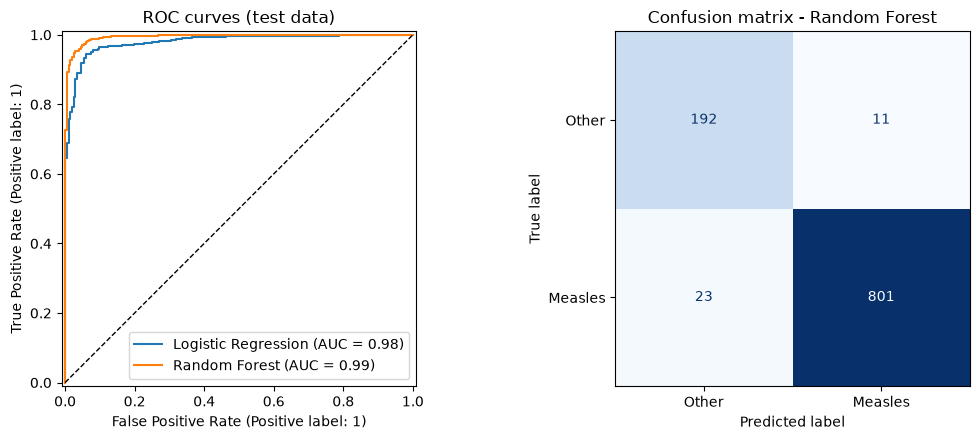

In [8]:
plt.figure(figsize=(11, 4.5))

ax1 = plt.subplot(1, 2, 1)
RocCurveDisplay.from_estimator(log_reg, X_test, y_test, name="Logistic Regression", ax=ax1)
RocCurveDisplay.from_estimator(forest, X_test, y_test, name="Random Forest", ax=ax1)
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.title("ROC curves (test data)")

ax2 = plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(confusion_matrix(y_test, best_predictions), display_labels=["Other", "Measles"]).plot(
    ax=ax2, cmap="Blues", colorbar=False)
plt.title(f"Confusion matrix - {best_name}")

plt.tight_layout()
plt.savefig("outputs/roc_and_confusion_matrix.png", dpi=200)
plt.show()

## 5. Feature importance (Q4.3)

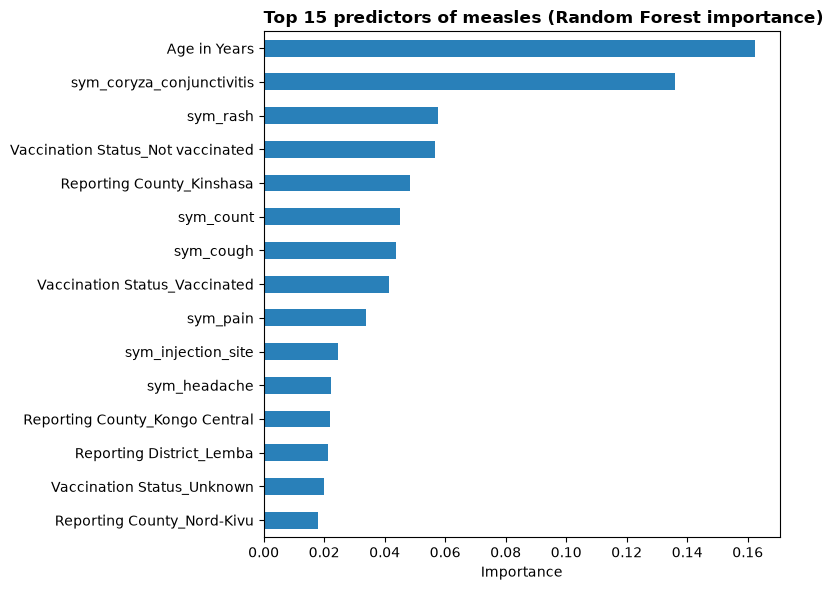

Age in Years                         0.1625
sym_coryza_conjunctivitis            0.1359
sym_rash                             0.0576
Vaccination Status_Not vaccinated    0.0566
Reporting County_Kinshasa            0.0485
sym_count                            0.0450
sym_cough                            0.0437
Vaccination Status_Vaccinated        0.0414
sym_pain                             0.0338
sym_injection_site                   0.0245
sym_headache                         0.0223
Reporting County_Kongo Central       0.0218
Reporting District_Lemba             0.0214
Vaccination Status_Unknown           0.0200
Reporting County_Nord-Kivu           0.0179
dtype: float64

In [9]:
importance = pd.Series(forest.best_estimator_.feature_importances_, index=X_train.columns)
top15 = importance.sort_values(ascending=False).head(15)

top15.sort_values().plot(kind="barh", figsize=(8, 6), color="#2980b9")
plt.title("Top 15 predictors of measles (Random Forest importance)", loc="left", fontweight="bold")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=200)
plt.show()

top15.round(4)

## 6. Changing the decision threshold (Q4.3)
By default a case is called measles when the predicted probability ≥ 0.5. Lowering the threshold catches **more** measles cases
(fewer false negatives) at the cost of more false alarms (false positives).

In [10]:
probabilities = best.predict_proba(X_test)[:, 1]
rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    predicted = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
    rows.append([threshold, round(tp / (tp + fn), 3), round(tp / (tp + fp), 3), fn, fp])

thresholds = pd.DataFrame(rows, columns=["threshold", "recall (measles)", "precision (measles)",
                                         "missed measles (FN)", "false alarms (FP)"])
thresholds.to_csv("outputs/phase4_threshold_table.csv", index=False)
results.to_csv("outputs/phase4_model_results.csv", index=False)
thresholds

,threshold,recall (measles),precision (measles),missed measles (FN),false alarms (FP)
0,0.2,0.996,0.964,3,31
1,0.3,0.992,0.975,7,21
2,0.4,0.985,0.983,12,14
3,0.5,0.972,0.986,23,11
4,0.6,0.960,0.990,33,8
5,0.7,0.938,0.994,51,5
